# Machine Learning Project 2026/27 — 90-Day Repeat Purchase Prediction

## Abstract

Everything & Then Some, a wholesale distributor, wants to know at the moment of each purchase whether the customer will buy again within 90 days, to target retention and replenishment actions. We treated this as binary classification on 6,534 purchase occasions from 2015–2025 and predicted 986 later purchases from 2025–2026.

Exploration showed that the target is defined by each customer's next purchase, so every feature must describe only the past and validation must respect time. Models were therefore assessed on five yearly expanding windows, each separated from its training data by a 90-day gap, and the last twelve months were kept as a sealed holdout. Cleaning removed 65 empty rows, turned placeholders and negative values into missing values and rebuilt many of them exactly from column definitions. We engineered rhythm and seasonality features, including a four-month buying cycle, and tested every optional choice; the customer table added no measurable information and was not joined. A majority vote of a correlation filter, recursive feature elimination and an L1 penalty removed about 60 % of the inputs without loss and rejected a pure-noise probe.

We benchmarked twelve algorithms from class, tuned six with 60-candidate random searches and tested soft voting. A tuned Extra Trees model ranked best (ROC-AUC 0.800 ± 0.023 across windows) and no ensemble improved it. With a decision threshold of 0.43 chosen for F1, the sealed holdout gave ROC-AUC 0.814 and F1 0.794, against 0.738 for always predicting a repeat and 0.763 for a homework-style logistic regression.

An open-ended study showed that customer history carries most of the signal, that the probabilities are reasonably calibrated but exposed to yearly drift, and that first purchases are almost unpredictable. For retention, ranking works well: the 20 % of purchases with the lowest probability are non-repeats three times out of four.

## How the project is organised

| Notebook | Outline section |
|---|---|
| `01_Business_and_Data_Exploration` | Contribution, Abstract, I. Business need, II.a Exploration |
| `02_Preprocessing` | II.b Cleaning and preparation, with each optional decision tested |
| `03_Feature_Selection` | III.a Feature-selection strategy |
| `04_Modelling_and_Optimisation` | III.b Benchmark of 12 algorithms, tuning, final model, sealed holdout |
| `05_Open_Ended` | IV. Can the model be trusted to drive commercial actions? |
| `06_Deployment` | V. Same pipeline applied to `test.csv`, Kaggle CSV |

All cleaning, feature, validation and scoring code lives in `project_pipeline.py`, so every notebook uses exactly the same recipe. Run the notebooks in order: 04 saves the final configuration that 05 and 06 read.

## How this project builds on Part 1 (the homework)

The final project repeats the homework workflow at full scale, as the homework brief intended ("a compact version of the same workflow"). Every notebook starts with a table saying what was **kept** from our Part 1 notebooks (`notebooks/01–04`), what was **changed** (and why), and what is **new**. Each section repeats this in a short note, and the code comments name the class week each technique comes from.

| Part 2 notebook | Built on (Part 1) | Main changes after the Part 1 review |
|---|---|---|
| 01 Exploration | `01_Exploration_notebook` | Same checks; adds the business framing, the leakage analysis of the target, the exact-sum columns and the four-month cycle; corrects the target definition ("*within* 90 days") |
| 02 Preprocessing | `02_Preprocessing` | Same cleaning rule, `log1p`, median / constant fill, one-hot and scaling; empty rows now really dropped; values rebuilt from definitions; one shared module instead of copies |
| 03 Feature selection | `03_Feature_Selection` | Same methods (filter, RFE, L1, tree importance, vote) and the same paired comparison; judged with three models and ROC-AUC; the vote is exported instead of tree importance |
| 04 Modelling | `04_Model` | Same chronological windows with a 90-day gap and the same refit-per-window pipeline; adds 11 algorithms, random search, a sealed holdout, the F1 floor and threshold tuning |
| 05 Open-ended | — | New (the homework had no open-ended section) |
| 06 Deployment | `04_Model`, Section 7 | Same "refit on all rows, predict `test.csv`"; adds a saved pipeline, input checks and the Kaggle file name |

The full list of issues found in Part 1 is in `docs/00_Homework_Review.md`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import pointbiserialr

# Part 1 copied its loading and cleaning code into every notebook; here it lives once in
# project_pipeline.py and every notebook imports it, so the notebooks cannot disagree.
import helpers.project_pipeline as pp

import importlib
importlib.reload(pp)


pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
BLUE, ORANGE, GREY = "#1779A8", "#C96A00", "#8C8C8C"

train, test, clientes = pp.load_raw(pp.find_data_folder())
print(f"train {train.shape}, test {test.shape}, clientes {clientes.shape}")

train (6534, 39), test (986, 38), clientes (1143, 13)


# I. Identifying the business need

**Context.** Everything & Then Some is a wholesaler whose customers buy at very irregular rhythms. The company wants to know, at the moment a purchase is registered, **whether the same customer will buy again within the next 90 days**, so that commercial effort goes where it changes something.

| Question | Answer for this project |
|---|---|
| Observation | One purchase occasion of one customer |
| Target | `repeat_purchase_90d`: 1 if the customer buys again within 90 days |
| Features | The current purchase, the customer's history *up to this purchase*, the sale context, the date |
| Prediction moment | When the purchase is registered: nothing that happens afterwards may be used |
| Decision | Rank purchases by repeat probability: the lowest get a retention contact, the highest feed replenishment and cross-selling plans |

**Which mistakes matter.** Predicting "repeat" for a customer who does not come back means a lost customer received no action. Predicting "no repeat" for a loyal customer means an unnecessary contact. Both matter, so the model must *rank* customers well (ROC-AUC), and the label threshold is a separate business choice.

## Model assessment strategy

The target looks 90 days into the future and the test file covers a **later** period than the training file, so the assessment copies that situation instead of shuffling rows:

1. **Sealed holdout** – the last 12 months of `train.csv`. Used **once**, at the end of notebook 04, to estimate how the chosen procedure performs on unseen, later purchases.
2. **Development rows** – purchases more than 90 days before the holdout starts, so no development label looks into the holdout period.
3. **Five yearly validation windows** inside the development rows (expanding window, a time-ordered version of `TimeSeriesSplit`). Each window trains only on purchases made **more than 90 days before it opens**: their labels are then fully known, exactly like the 98-day gap between the end of `train.csv` and the start of `test.csv`.
4. **Final model** – refitted on every usable labelled row before predicting `test.csv`.

Every choice in notebooks 02–05 (features, selection, algorithm, settings, threshold) is made on the five windows only.

In [2]:
design = pp.development_split(train)
display(pp.describe_folds(design))
print(f"Sealed holdout : {design.holdout_start.date()} to {train[pp.DATE].max().date()} ({len(design.X_hold)} rows)")
print(f"Kaggle test    : {test[pp.DATE].min().date()} to {test[pp.DATE].max().date()} ({len(test)} rows)")

,train from,train to,validate from,validate to,train rows,validation rows,validation repeat rate
fold,,,,,,,
1,2015-07-11,2018-08-21,2018-11-20,2019-11-19,1872,667,0.528
2,2015-07-11,2019-08-20,2019-11-20,2020-11-17,2503,658,0.588
3,2015-07-11,2020-08-02,2020-11-20,2021-11-16,3185,790,0.547
4,2015-07-11,2021-08-16,2021-11-19,2022-11-18,3900,652,0.486
5,2015-07-11,2022-08-20,2022-11-19,2023-11-18,4648,764,0.564


Sealed holdout : 2024-02-17 to 2025-02-15 (742 rows)
Kaggle test    : 2025-05-24 to 2026-10-06 (986 rows)


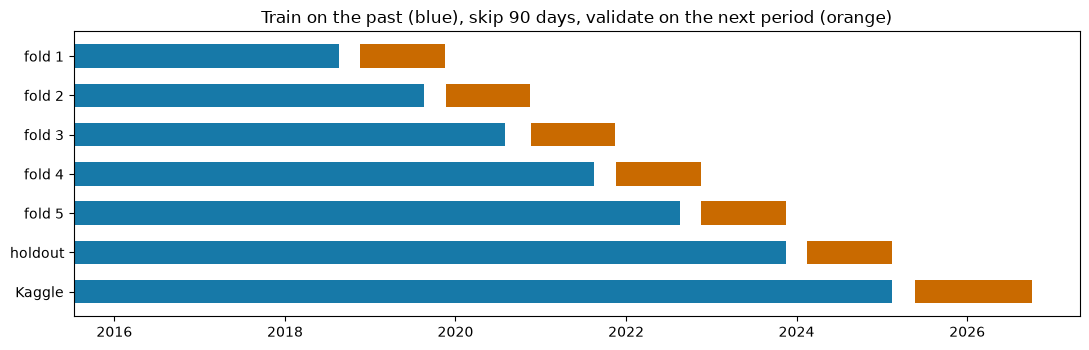

In [3]:
# Timeline of the design: training (blue), the 90-day gap (white), validation (orange).
fig, ax = plt.subplots(figsize=(11, 3.6))
dates = design.X_dev[pp.DATE]
first_day = train[pp.DATE].min()
rows = [(f"fold {i}", dates.iloc[a].max(), dates.iloc[b].min(), dates.iloc[b].max())
        for i, (a, b) in enumerate(design.folds, start=1)]
rows.append(("holdout", design.development_end, design.holdout_start, train[pp.DATE].max()))
rows.append(("Kaggle", train[pp.DATE].max(), test[pp.DATE].min(), test[pp.DATE].max()))
for y, (label, train_end, val_start, val_end) in enumerate(rows[::-1]):
    ax.barh(y, train_end - first_day, left=first_day, color=BLUE, height=0.6)
    ax.barh(y, val_end - val_start, left=val_start, color=ORANGE, height=0.6)
ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]])
ax.set_title("Train on the past (blue), skip 90 days, validate on the next period (orange)")
plt.tight_layout()
plt.show()

Every validation window is a *future* period for its model, and the holdout and Kaggle rows sit in the same position relative to their training data.

**Metrics** (chosen before seeing any result):
- **ROC-AUC** compares models. It measures how well purchases are *ranked*, over every threshold, so a model is not penalised only because its probabilities are shifted.
- **F1** of the repeat class is the competition metric. It is reported at the threshold chosen on the validation windows (notebook 04), always next to its **floor**: the F1 of predicting "repeat" for everyone.
- **Balanced accuracy** checks that the non-repeat class, the one retention actions target, is not sacrificed.

# II. Data exploration

## 2.1 What was received


> **Kept from Part 1:** the shapes of the three tables, the column groups and the train/test date ranges (Part 1, Sections 1, 2 and 4.4).
>
> **New in Part 2:** customers per table and how many test customers already appear in train.

In [4]:
summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "customers": [train[pp.CUSTOMER].nunique(), test[pp.CUSTOMER].nunique()],
    "first purchase date": [train[pp.DATE].min().date(), test[pp.DATE].min().date()],
    "last purchase date": [train[pp.DATE].max().date(), test[pp.DATE].max().date()],
}, index=["train.csv", "test.csv"])
display(summary)
seen = test[pp.CUSTOMER].isin(train[pp.CUSTOMER]).mean()
print(f"Test purchases whose customer also appears in train: {seen:.1%}")
print("Purchases per customer in train (median, max):",
      train[pp.CUSTOMER].value_counts().median(), train[pp.CUSTOMER].value_counts().max())

,rows,customers,first purchase date,last purchase date
train.csv,6534,610,2015-07-11,2025-02-15
test.csv,986,206,2025-05-24,2026-10-06


Test purchases whose customer also appears in train: 94.5%
Purchases per customer in train (median, max): 4.0 277


| Group | Columns |
|---|---|
| Identifiers | `ID` (row / submission key), `customer_id` (join key) |
| Current purchase | `Total a Pagar`, `Total Bruto`, `Total Liquido`, `Total Imp_`, `Total Portes`, `Total Desc_ Global`, `Total Desc_ Linha`, `Custo`, `N_ Detalhes`, `invoice_count_current_purchase` |
| History timing | `days_since_previous_purchase`, `customer_tenure_days`, `prior_purchase_count`, `prior_mean_gap_days`, `prior_std_gap_days` |
| History value | `prior_total_spend`, `prior_mean/std/min/max_purchase_value` |
| Rolling activity | `purchase_count_30/90/180/365d`, `spend_30/90/180/365d` |
| Sale context | `payment_type`, `salesperson`, `commercial_zone`, `transport_method`, `warehouse`, `document_series` |
| Other | `purchase_date`, `random_noise` |

Train covers almost ten years and test the following 16 months, starting 98 days after train ends. Almost every test customer is already known, but purchases per customer are very uneven: half of the customers have four purchases or fewer, one has 277.

## 2.2 The target and how it moves over time


> **Kept from Part 1:** the class balance (56 % repeat) and the conclusion that no resampling is needed (Part 1, Section 5).
>
> **Changed:** Part 1 noted that "always repeat" is right 56 % of the time but never turned this into an F1 floor; here it is computed (≈ 0.72) and used in every later comparison.
>
> **New in Part 2:** the repeat rate per year, which shows the drift that motivates several validation windows.

Repeat rate: 0.559  ->  F1 of always predicting 'repeat': 0.717


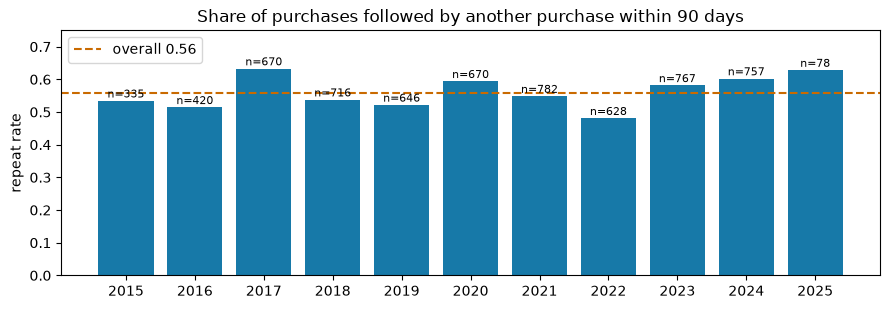

In [5]:
repeat_rate = train[pp.TARGET].mean()
print(f"Repeat rate: {repeat_rate:.3f}  ->  F1 of always predicting 'repeat': {2 * repeat_rate / (1 + repeat_rate):.3f}")

yearly = train.groupby(train[pp.DATE].dt.year)[pp.TARGET].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(yearly.index.astype(int).astype(str), yearly["mean"], color=BLUE)
ax.axhline(repeat_rate, color=ORANGE, linestyle="--", label=f"overall {repeat_rate:.2f}")
for x, (rate, n) in enumerate(yearly.itertuples(index=False)):
    ax.text(x, rate + 0.01, f"n={n}", ha="center", fontsize=8)
ax.set(ylim=(0, 0.75), ylabel="repeat rate", title="Share of purchases followed by another purchase within 90 days")
ax.legend()
plt.tight_layout()
plt.show()

The classes are close to balanced (56 % repeat), so no resampling is needed. Two consequences:
- **F1 has a high floor (≈ 0.72):** a model is only useful if it clearly beats "everyone repeats", which is why F1 is always shown with its floor.
- **The repeat rate drifts between 0.48 and 0.63 from year to year.** A single validation period could be unusually easy or hard, so the five yearly windows show how stable each result is.

## 2.3 Data quality
### 2.3.1 Empty rows and duplicates


> **Kept from Part 1:** the 65 rows that are missing almost everything, the 603 first purchases with structurally missing history, the 1e9 placeholders and the negative values (Part 1, Sections 4.1–4.3).
>
> **Changed:** Part 1 counted 10 duplicated rows and said to treat them separately; they turn out to be empty rows, so dropping the empty rows removes them. Part 1 also said to drop the empty rows but its preprocessing kept them; here they are dropped everywhere.
>
> **New in Part 2:** the two total columns that are exact sums of others, and rates of invalid values in `test.csv`.

In [6]:
empty = pp.empty_rows(train)
copies = train.drop(columns=pp.ID_COLUMN).duplicated(keep=False)
print(f"Rows with every purchase field missing: {empty.sum()} (test: {pp.empty_rows(test).sum()})")
print(f"Rows identical to another row (ignoring ID): {copies.sum()}, of which empty: {(copies & empty).sum()}")
print(f"Repeat rate of the empty rows: {train.loc[empty, pp.TARGET].mean():.2f}")

Rows with every purchase field missing: 65 (test: 0)
Rows identical to another row (ignoring ID): 16, of which empty: 16
Repeat rate of the empty rows: 0.51


The 65 empty rows hold only `ID`, `customer_id` and the target: no amount, no history and **no date**. They cannot be placed in time, so they cannot enter a chronological validation, and they would teach the model nothing but the average repeat rate. The 16 "duplicated" rows are all empty rows of the same customers, not repeated purchases. Test has no such rows. **Decision: drop the 65 empty rows.**

### 2.3.2 Impossible values

In [7]:
numeric = pp.RAW_NUMERIC
invalid = pd.DataFrame({
    "negative (train)": (train[numeric] < 0).sum(),
    "1e9 placeholder (train)": (train[numeric] >= pp.SENTINEL).sum(),
    "negative (test)": (test[numeric] < 0).sum(),
    "1e9 placeholder (test)": (test[numeric] >= pp.SENTINEL).sum(),
})
display(invalid[invalid.sum(axis=1) > 0])

,negative (train),1e9 placeholder (train),negative (test),1e9 placeholder (test)
days_since_previous_purchase,16,0,2,0
prior_mean_gap_days,16,0,2,0
prior_mean_purchase_value,16,16,2,2
spend_365d,15,15,2,2


Negative day counts, a negative average purchase value and a spend of exactly 1,000,000,000 cannot be true. They appear in train **and** test, in the same four columns, so the treatment must be a rule applied to every row, not a deletion of training rows. **Decision: mark them as missing (week 3: find invalid values first, then treat them as missing).** Large but possible values (big orders) are kept and their long tails are compressed with `log1p` in preprocessing.

### 2.3.3 Columns that are exact functions of other columns

In [8]:
usable = train[~empty]
count = usable["prior_purchase_count"]
mean_value_ok = usable["prior_mean_purchase_value"].between(0, pp.SENTINEL - 1)
gap_ok = (count >= 2) & usable["prior_mean_gap_days"].ge(0) & usable["days_since_previous_purchase"].ge(0)
checks = {
    "Total a Pagar = Total Liquido + Total Imp_":
        np.isclose(usable["Total a Pagar"], usable["Total Liquido"] + usable["Total Imp_"], atol=0.02),
    "Total Bruto = Total Liquido + Desc. Linha + Desc. Global":
        np.isclose(usable["Total Bruto"], usable["Total Liquido"] + usable["Total Desc_ Linha"]
                   + usable["Total Desc_ Global"], atol=0.02),
    "prior_mean_purchase_value = prior_total_spend / prior_purchase_count":
        np.isclose(usable.loc[mean_value_ok & (count > 0), "prior_mean_purchase_value"],
                   (usable["prior_total_spend"] / count)[mean_value_ok & (count > 0)], atol=0.01),
    "prior_mean_gap_days = (tenure - days_since_previous) / (count - 1)":
        np.isclose(usable.loc[gap_ok, "prior_mean_gap_days"],
                   ((usable["customer_tenure_days"] - usable["days_since_previous_purchase"]) / (count - 1))[gap_ok], atol=0.01),
    "days_since_previous_purchase = tenure when count = 1":
        np.isclose(usable.loc[count == 1, "days_since_previous_purchase"].dropna(),
                   usable.loc[(count == 1) & usable["days_since_previous_purchase"].notna(), "customer_tenure_days"]),
}
display(pd.Series({name: f"{np.mean(ok):.1%}" for name, ok in checks.items()}, name="rows where it holds").to_frame())

,rows where it holds
Total a Pagar = Total Liquido + Total Imp_,100.0%
Total Bruto = Total Liquido + Desc. Linha + Desc. Global,100.0%
prior_mean_purchase_value = prior_total_spend / prior_purchase_count,99.2%
prior_mean_gap_days = (tenure - days_since_previous) / (count - 1),100.0%
days_since_previous_purchase = tenure when count = 1,99.3%


- `Total a Pagar` and `Total Bruto` are **exact sums** of other columns. They add no information, only redundancy. **Decision: drop them.**
- The average purchase value and the average gap between purchases follow from their definitions in 99 % and 100 % of the rows where they are valid. **Decision: where these values are missing or invalid, rebuild them from the definition** instead of guessing a median. This repairs most of the impossible values found above with the true value. The same idea gives `days_since_previous_purchase` for customers with one earlier purchase, and `spend_365d` when the 365-day count is 0 or covers all earlier purchases.

### 2.3.4 Missing values: structural or random?

In [9]:
structural_rule = {   # history fields that cannot exist for a short history
    "days_since_previous_purchase": count == 0,
    "prior_mean_purchase_value": count == 0,
    "prior_min_purchase_value": count == 0,
    "prior_max_purchase_value": count == 0,
    "prior_std_purchase_value": count <= 1,
    "prior_mean_gap_days": count <= 1,
    "prior_std_gap_days": count <= 2,
}
rows = []
for column in usable.columns[usable.isna().any()]:
    missing = usable[column].isna()
    structural = missing & structural_rule.get(column, pd.Series(False, index=usable.index))
    other = missing & ~structural
    rows.append({"column": column, "missing": missing.sum(), "structural (short history)": structural.sum(),
                 "other": other.sum(),
                 "repeat rate when 'other' missing": round(usable.loc[other, pp.TARGET].mean(), 3) if other.any() else None})
display(pd.DataFrame(rows).set_index("column").sort_values("missing", ascending=False))
print(f"Overall repeat rate: {usable[pp.TARGET].mean():.3f}")

,missing,structural (short history),other,repeat rate when 'other' missing
column,,,,
prior_std_gap_days,1413,1413,0,NaN
prior_mean_gap_days,1243,1048,195,0.656
prior_std_purchase_value,1048,1048,0,NaN
prior_mean_purchase_value,797,603,194,0.582
days_since_previous_purchase,796,603,193,0.570
prior_min_purchase_value,603,603,0,NaN
prior_max_purchase_value,603,603,0,NaN
transport_method,196,0,196,0.551
spend_365d,195,0,195,0.564


Overall repeat rate: 0.560


Two different kinds of missingness:
- **Structural.** A first purchase has no previous purchase, a customer with one earlier purchase has no gap between purchases, and so on. These values are not lost: they *do not exist*, and "this is a new customer" is itself informative. **Decision: impute them (median, fitted on training rows) and add a `first_purchase` flag** so a model can tell a real median from a short history.
- **Random.** About 195 extra values per column are missing with no pattern. Their repeat rate (0.55–0.66) is close to that of comparable rows (0.56 overall, 0.60 for customers with at least two earlier purchases, which is who can have a missing gap), so a missing flag would carry little signal. **Decision: median for numbers, an explicit `Missing` level for categories** (both fitted inside each training split).

## 2.4 How the target was built, and what it forbids


> **Changed:** Part 1 described the target as a purchase "after 90 days"; it is a purchase *within* 90 days.
>
> **New in Part 2:** the target is rebuilt from each customer's next purchase (99.1 % agreement), which explains why only past information may be used and why validation must leave a 90-day gap. (Part 1 already used the gap without showing why.)

In [10]:
ordered = usable.sort_values([pp.CUSTOMER, pp.DATE])
days_to_next = (ordered.groupby(pp.CUSTOMER)[pp.DATE].shift(-1) - ordered[pp.DATE]).dt.days
next_within_90 = (days_to_next <= pp.HORIZON_DAYS).astype(int)
display(pd.crosstab(next_within_90.rename("next row of the same customer within 90 days"),
                    ordered[pp.TARGET]))
print(f"Agreement with the target: {(next_within_90 == ordered[pp.TARGET]).mean():.1%}")

repeat_purchase_90d,0,1
next row of the same customer within 90 days,,
0,2848,56
1,0,3565


Agreement with the target: 99.1%


In 99.1 % of the rows the target is simply "the same customer has another row within the next 90 days" (the few exceptions are purchases near the end of the file, whose next purchase is outside it). This is the most important fact for the whole pipeline, because it shows exactly how leakage would happen:

- Any feature computed from **later** rows (for example customer-level averages over the whole table, or how many rows a customer has in total) would contain the answer. **Every feature must describe only the past**, as the supplied history columns do.
- `customer_id` must not become a feature, and target encoding of customers is avoided.
- **Shuffled K-fold is wrong here**: it would train on purchases made *after* the validation purchases of the same customer. This is why the assessment strategy in Section I is chronological, with a 90-day gap.

The same structure exists in `test.csv` (later purchases of the same customers are visible in it). Using it would mean reading the future at prediction time, so we deliberately do not.

## 2.5 What separates repeat from non-repeat purchases


> **Kept from Part 1:** the medians by class and the correlation of every numeric column with the target (Part 1, Sections 7.1–7.3, week 3).
>
> **Changed:** computed after cleaning, so invalid values no longer distort the picture.

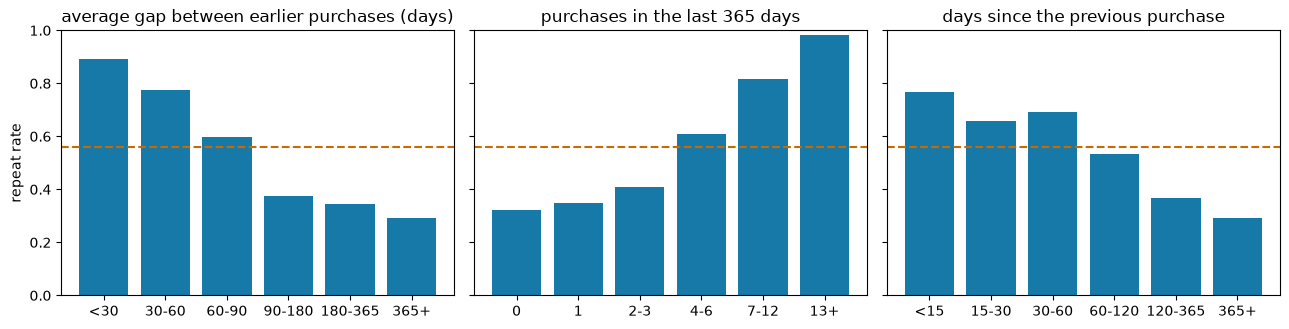

Repeat rate of first purchases: 0.33


In [11]:
cleaned = pp.clean_purchases(usable)

def repeat_rate_by(column, bins, labels):
    groups = pd.cut(cleaned[column], bins=bins, labels=labels, right=False)
    return cleaned.groupby(groups, observed=True)[pp.TARGET].agg(["mean", "size"])

panels = {
    "average gap between earlier purchases (days)":
        repeat_rate_by("prior_mean_gap_days", [0, 30, 60, 90, 180, 365, np.inf],
                       ["<30", "30-60", "60-90", "90-180", "180-365", "365+"]),
    "purchases in the last 365 days":
        repeat_rate_by("purchase_count_365d", [0, 1, 2, 4, 7, 13, np.inf],
                       ["0", "1", "2-3", "4-6", "7-12", "13+"]),
    "days since the previous purchase":
        repeat_rate_by("days_since_previous_purchase", [0, 15, 30, 60, 120, 365, np.inf],
                       ["<15", "15-30", "30-60", "60-120", "120-365", "365+"]),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (title, table) in zip(axes, panels.items()):
    ax.bar(table.index.astype(str), table["mean"], color=BLUE)
    ax.axhline(cleaned[pp.TARGET].mean(), color=ORANGE, linestyle="--")
    ax.set(title=title, ylim=(0, 1))
axes[0].set_ylabel("repeat rate")
plt.tight_layout()
plt.show()
print(f"Repeat rate of first purchases: {cleaned.loc[cleaned['prior_purchase_count'] == 0, pp.TARGET].mean():.2f}")

In [12]:
# Medians by class for a few columns from each group (cleaned values).
columns = ["prior_mean_gap_days", "purchase_count_365d", "days_since_previous_purchase",
           "prior_purchase_count", "customer_tenure_days", "Total Liquido", "N_ Detalhes", "random_noise"]
display(cleaned.groupby(pp.TARGET)[columns].median().T.round(2))

repeat_purchase_90d,0,1
prior_mean_gap_days,102.62,55.76
purchase_count_365d,2.00,5.00
days_since_previous_purchase,105.00,37.00
prior_purchase_count,6.00,17.00
customer_tenure_days,781.00,1032.00
Total Liquido,362.19,422.05
N_ Detalhes,12.00,10.00
random_noise,-0.04,-0.05


The customer's **rhythm** dominates: customers whose earlier purchases were less than 30 days apart repeat in 89 % of cases and those with gaps over 90 days in only about a third; the number of purchases in the last year moves the rate from 32 % (none) to 98 % (13 or more). Recency works the same way (77 % within 15 days, 29 % after a year). First purchases repeat in only a third of cases.

The **current purchase** barely matters: the median amount and number of lines are similar for both classes. `random_noise` has the same median in both classes. All columns are right-skewed with long tails, which supports `log1p` before scaling.

## 2.6 A four-month buying cycle in the calendar


> **New in Part 2:** Part 1 used `purchase_date` only for splitting. The repeat rate by calendar month reveals a cycle in months 3, 7 and 11, which becomes the `purchase_month` feature.

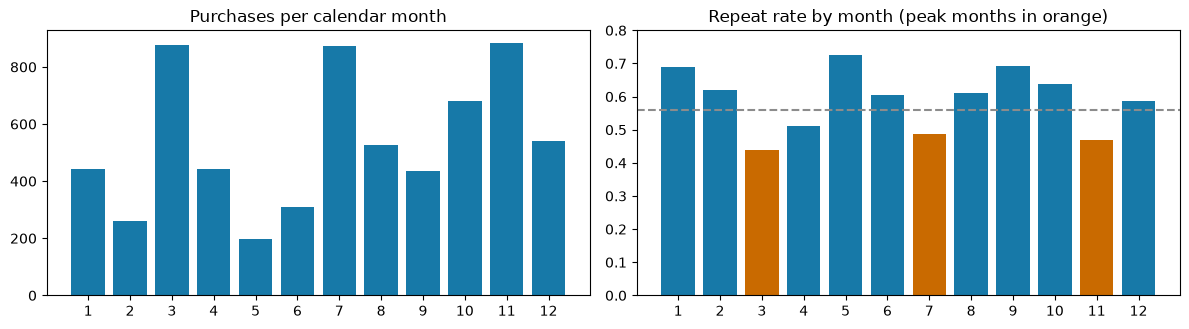

purchase_date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
three busiest months,"[7, 9, 10]","[3, 7, 10]","[8, 11, 12]","[3, 7, 11]","[3, 7, 11]","[3, 7, 10]","[3, 7, 11]","[3, 7, 11]","[3, 7, 11]","[3, 7, 11]","[1, 2]"


test.csv purchases per month:


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2025,0,0,0,0,5,51,90,81,46,48,109,35
2026,63,83,29,53,16,60,96,62,45,14,0,0


In [13]:
month = cleaned[pp.DATE].dt.month
by_month = cleaned.groupby(month)[pp.TARGET].agg(["mean", "size"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].bar(by_month.index, by_month["size"], color=BLUE)
axes[0].set(title="Purchases per calendar month", xticks=range(1, 13))
axes[1].bar(by_month.index, by_month["mean"], color=[ORANGE if m in (3, 7, 11) else BLUE for m in by_month.index])
axes[1].axhline(cleaned[pp.TARGET].mean(), color=GREY, linestyle="--")
axes[1].set(title="Repeat rate by month (peak months in orange)", xticks=range(1, 13), ylim=(0, 0.8))
plt.tight_layout()
plt.show()

peaks = cleaned.groupby(cleaned[pp.DATE].dt.year).apply(
    lambda g: sorted(g[pp.DATE].dt.month.value_counts().nlargest(3).index), include_groups=False)
display(peaks.rename("three busiest months").to_frame().T)
print("test.csv purchases per month:")
display(pd.crosstab(test[pp.DATE].dt.year.rename("year"), test[pp.DATE].dt.month.rename("month")))

From 2018 to 2024 the three busiest months are 3, 7 and 11 (in the anonymised calendar) in almost every year: customers seem to order in a roughly four-month cycle. A purchase made in a peak month is followed by another purchase within 90 days less often (44–49 %), because the next peak is about four months away; purchases between peaks repeat more often (up to 72 %).

The dates are anonymised, but intervals are preserved, so a repeating cycle survives the anonymisation. In `test.csv` July and November 2025 and July 2026 are again busy, but March 2026 is not, so the cycle may be weaker in the test period. **Decision: add the purchase month as a categorical candidate feature** (no order assumed between months); notebooks 02 and 03 decide whether it earns its place, and Section IV measures how much the model relies on it.

## 2.7 Categorical variables


> **Kept from Part 1:** the frequency tables and repeat rate per level (Part 1, Sections 6.2 and 7.4).
>
> **New in Part 2:** how many levels belong to a single customer, which matters for one-hot encoding.

In [14]:
rows = []
for column in pp.CATEGORICAL:
    values = usable[column]
    counts = values.value_counts()
    rate = usable.groupby(column)[pp.TARGET].mean()[counts[counts >= 30].index]
    customers = usable.groupby(column)[pp.CUSTOMER].nunique()
    rows.append({"variable": column, "levels": values.nunique(), "missing": values.isna().sum(),
                 "share of top level": round(counts.iloc[0] / counts.sum(), 2),
                 "levels with < 10 rows": int((counts < 10).sum()),
                 "levels used by 1 customer": int((customers == 1).sum()),
                 "repeat rate range (levels >= 30 rows)": f"{rate.min():.2f} - {rate.max():.2f}"})
display(pd.DataFrame(rows).set_index("variable"))

,levels,missing,share of top level,levels with < 10 rows,levels used by 1 customer,repeat rate range (levels >= 30 rows)
variable,,,,,,
payment_type,9,195,0.73,3,0,0.33 - 0.95
salesperson,9,194,0.65,2,0,0.37 - 0.62
commercial_zone,5,0,0.97,2,2,0.36 - 0.57
transport_method,80,196,0.18,40,40,0.15 - 0.98
warehouse,2,195,1.00,0,0,0.56 - 0.56
document_series,3,0,0.42,0,0,0.56 - 0.56


- `payment_type`, `salesperson` and `transport_method` show clearly different repeat rates between their common levels (for example one payment type repeats in 95 % of its purchases).
- `commercial_zone` and `warehouse` are almost constant, and the three `document_series` have the same repeat rate: probably uninformative, which feature selection should confirm.
- `transport_method` has 80 levels and many are used by a single customer, so their columns partly *identify customers*. Because most test customers are known, this can still carry real information about the future, but it can also overfit. **Decision: one-hot encode inside the pipeline and let the validation windows decide whether rare levels should be merged** (`min_frequency`, tuned in notebook 04).

## 2.8 Identifier-like fields


> **Kept from Part 1:** `customer_id` and `random_noise` are not used as inputs (Part 1, Section 3.10 of feature selection).
>
> **New in Part 2:** `random_noise` is kept as a probe for feature selection (notebook 03).

In [15]:
noise = usable[["random_noise", pp.TARGET]].dropna()
r, p = pointbiserialr(noise[pp.TARGET], noise["random_noise"])
print(f"random_noise vs target: point-biserial r = {r:.3f} (p = {p:.2f})")
print(f"customer_id: {usable[pp.CUSTOMER].nunique()} distinct values; ID: unique per row = {train[pp.ID_COLUMN].is_unique}")

random_noise vs target: point-biserial r = -0.012 (p = 0.34)
customer_id: 607 distinct values; ID: unique per row = True


`random_noise` shows no relationship with the target (r ≈ −0.01, p ≈ 0.34). `ID` only identifies the row and `customer_id` only identifies the customer: their numeric values have no meaning, and a customer identifier would let a model memorise customers instead of learning behaviour. **Decision: none of the three is a model input.** `random_noise` is reused in notebook 03 as a **probe**: a selection method that keeps it is selecting noise.

## 2.9 The optional customer table (`clientes.csv`)


> **Kept from Part 1:** the checks that every customer is in the table and that most columns are empty or redundant (Part 1, Section 8).
>
> **Changed:** Part 1 dropped the table without testing it; here the join is tested in notebook 02.

In [16]:
print(f"One row per customer: {clientes[pp.CUSTOMER].is_unique}; every train/test customer present: "
      f"{train[pp.CUSTOMER].isin(clientes[pp.CUSTOMER]).all() and test[pp.CUSTOMER].isin(clientes[pp.CUSTOMER]).all()}")
display(pd.DataFrame({"missing %": (clientes.isna().mean() * 100).round(1),
                      "distinct values": clientes.nunique()}).T)

joined = usable.merge(clientes, on=pp.CUSTOMER, how="left")
years_as_client = joined[pp.DATE].dt.year - joined["customer_since_year"]
print(f"Correlation of (purchase year - customer_since_year) with customer_tenure_days: "
      f"{np.corrcoef(years_as_client, joined['customer_tenure_days'].fillna(0))[0, 1]:.2f}")
display(pd.crosstab(joined["country_or_region"], joined["Total Imp_"].eq(0), margins=True)
        .rename(columns={False: "taxed purchases", True: "zero-tax purchases"}))

One row per customer: True; every train/test customer present: True


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
missing %,0.0,0.0,10.0,50.6,13.9,47.8,6.2,14.9,52.3,0.5,100.0,0.0,0.0
distinct values,1143.0,11.0,37.0,10.0,183.0,417.0,271.0,828.0,511.0,1120.0,0.0,1141.0,12.0


Correlation of (purchase year - customer_since_year) with customer_tenure_days: 0.92


Total Imp_,taxed purchases,zero-tax purchases,All
country_or_region,,,
Country CT10: Land of The Final Version,6252,4,6256
Country CT4: Land of The Final Version,0,1,1
Country CT5: Land of The Final Version,1,193,194
Country CT6: Land of The Final Version,3,5,8
Country CT7: Land of The Final Version,0,8,8
Country CT8: Land of The Final Version,0,1,1
Country CT9: Land of The Final Version,0,1,1
All,6256,213,6469


Most columns of `clientes.csv` are empty (`customer_type` 100 %), almost unique per customer (`address`, `company_name`, `street`) or very fine-grained locations; those would only identify customers. The three usable candidates largely repeat information already in the purchases:
- `customer_since_year` follows `customer_tenure_days` (r ≈ 0.9; it is also capped at 2015, the first year of data);
- `country_or_region`: 97 % of purchases come from one country, and the second country is essentially the set of **zero-tax purchases** (exports), already visible through `Total Imp_` and the engineered `tax_rate`;
- `commercial_region` has 37 levels and mostly subdivides the main country.

**Decision: test the join instead of assuming it** — notebook 02 adds these three columns and compares the validation windows with and without them.

## 2.10 Key insights and the decisions they drive


> **Changed:** Part 1's summary listed insights; this table links each insight to the decision it causes and the notebook where it is applied.

| Insight | Decision | Where |
|---|---|---|
| Target = next purchase of the same customer within 90 days | Only past information as features; chronological validation with a 90-day gap; no customer IDs | Section I, all notebooks |
| Repeat rate drifts 0.48–0.63 by year; F1 floor ≈ 0.72 | Five yearly windows; report F1 with its floor; compare models with ROC-AUC | 04 |
| 65 empty, undated rows (all the "duplicates") | Drop | 02 |
| 1e9 placeholders and negatives, in train and test | Mark as missing, then rebuild from definitions where possible | 02 |
| `Total a Pagar`, `Total Bruto` are exact sums | Drop | 02 |
| Structural vs random missingness | Median (train-fitted) + `first_purchase` flag; `Missing` level for categories | 02 |
| Customer rhythm dominates; long right tails | `log1p`, then scaling; ratio features describing rhythm (`recency_ratio`, `purchases_per_year`, …) | 02 |
| Four-month calendar cycle (weaker in test) | `purchase_month` as a categorical candidate, tested | 02, 03, 05 |
| Rare transport levels identify customers | One-hot; rare-level merging tuned | 02, 04 |
| `random_noise`, `ID`, `customer_id` | Not inputs; noise used as a selection probe | 03 |
| `clientes.csv` mostly redundant | Join tested on the validation windows | 02 |